Deliverable 1

Ida Sofie Ramsli & Emilie Marthinsen Kålås




------------------------------------------------------
------------------------Task 1------------------------

Data retrieved from frost.met.no!


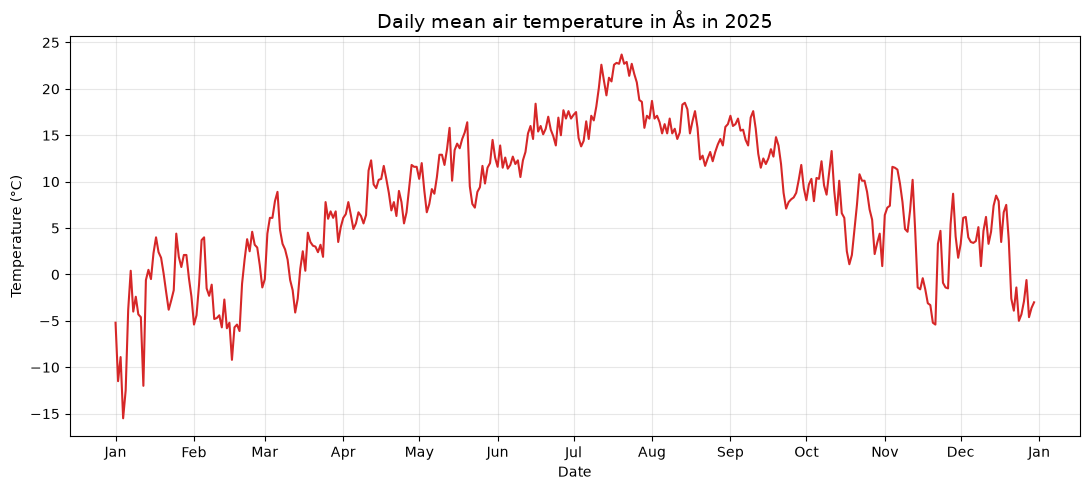


Summary of daily mean air temperature, 2025
------------------------------------------
Statistic  Temperature (°C)
     Mean               7.9
   Median               8.4
      Min             -15.5
      Max              23.7


In [ ]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates



client_id_file = Path.home() / "frost_client_id.txt"       # reads the client ID from a file in the home directory
client_id = client_id_file.read_text().strip()             # removes any spaces from the client ID string

endpoint = "https://frost.met.no/observations/v0.jsonld"    # Frost API endpoint for observations
parameters = {                                              # parameters for the API request
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}



r = requests.get(endpoint, parameters, auth=(client_id, ""))    # make the GET request to the Frost API with the specified parameters and authentication
json_data = r.json()                                            # extract the data from the response

if r.status_code == 200:                                  # check if the request was successful (status code 200 indicates success)
   data = json_data["data"]                                 # extract the "data" field from the JSON response
   print('Data retrieved from frost.met.no!')
else: 
    print(f"Error: {r.status_code} - {json_data['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                      # exit the program if there was an error with the request

df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)      # creates a dataframe from the rows list, sorts it by time, and resets the index



rows = []                                   # create an empty list to store the data rows for the DataFrame
for item in json_data["data"]:              # iterate through each item in the "data" field
    observation = item["observations"][0]   # one daily mean per reference time
    rows.append(                            # adds the data for each observation to the rows list as a dictionary with keys "time" and "temperature"
        {
            "time": pd.to_datetime(item["referenceTime"]),        
            "temperature": observation["value"],
        }
    )



fig, ax = plt.subplots(figsize=(11, 5))         # creates a figure and axes for the plot with a specified size
ax.plot(df["time"], df["temperature"], color="tab:red")      # plots the date on the x-axis and daily mean air temperature data on the y-axis
ax.set_title("Daily mean air temperature in Ås in 2025", fontsize=14)      
ax.set_xlabel("Date")    
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel("Temperature (°C)")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


temp = df["temperature"]
summary = pd.DataFrame(                         # creates a summary of statistics for the daily mean air temperature
    {
        "Statistic": ["Mean", "Median", "Min", "Max"],
        "Temperature (°C)": [temp.mean(), temp.median(), temp.min(), temp.max()],
    }
)

print("\nSummary of daily mean air temperature, 2025")
print("------------------------------------------")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.1f}"))


------------------------------------------------------
------------------------Task 2------------------------

Temperature data retrieved from frost.met.no!
Precipitation data retrieved from frost.met.no!


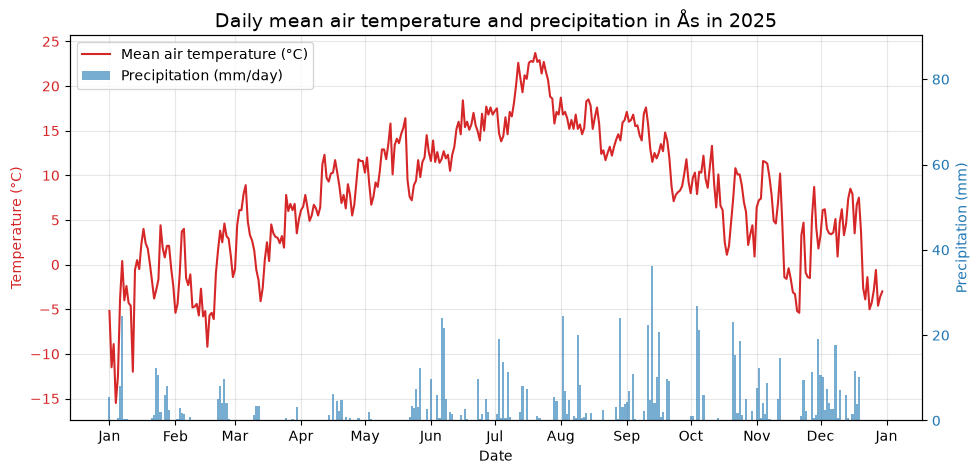

In [ ]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates



client_id_file = Path.home() / "frost_client_id.txt"       # reads the client ID from a file in the home directory
client_id = client_id_file.read_text().strip()             # removes any spaces from the client ID string

endpoint = "https://frost.met.no/observations/v0.jsonld"    # Frost API endpoint for observations




parameters = {                                              # parameters for the API request (daily mean air temperature)
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))    # make the GET request to the Frost API with the specified parameters and authentication
json_data = r.json()                                            # extract the data from the response

if r.status_code == 200:                                  # check if the request was successful (status code 200 indicates success)
    print('Temperature data retrieved from frost.met.no!')
else:
    print(f"Error: {r.status_code} - {json_data['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                     # stop the script here so the later code does not crash with a confusing KeyError

rows = []                                   # create an empty list to store the data rows for the DataFrame
for item in json_data["data"]:              # iterate through each item in the "data" field
    observation = item["observations"][0]   # one daily mean per reference time
    rows.append(                            # adds the data for each observation to the rows list as a dictionary with keys "time" and "temperature"
        {
            "time": pd.to_datetime(item["referenceTime"]),
            "temperature": observation["value"],
        }
    )

df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)      # creates a dataframe from the rows list, sorts it by time, and resets the index




parameters_precipitation = {                                # parameters for the API request (precipitation over 24 hours)
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r_precipitation = requests.get(endpoint, parameters_precipitation, auth=(client_id, ""))    # make the GET request to the Frost API with the precipitation parameters
json_precipitation = r_precipitation.json()                                                 # extract the data from the response



if r_precipitation.status_code == 200:                           # check if the request was successful (status code 200 indicates success)
    print('Precipitation data retrieved from frost.met.no!')
else:
    print(f"Error: {r_precipitation.status_code} - {json_precipitation['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                                            # stop the script here

rows_precipitation = []                                # create an empty list to store the data rows for the DataFrame
for item in json_precipitation["data"]:                # iterate through each item in the "data" field
    observation = item["observations"][0]              # one daily sum per reference time
    rows_precipitation.append(                         # adds the data for each observation to the list as a dictionary with keys "time" and "precipitation"
        {
            "time": pd.to_datetime(item["referenceTime"]),
            "precipitation": observation["value"],
        }
    )



df_precipitation = pd.DataFrame(rows_precipitation).sort_values("time").reset_index(drop=True)   # creates a dataframe from the rows list, sorts it by time, and resets the index

df_both = pd.merge(df, df_precipitation, on="time", how="outer").sort_values("time")      # combines temperature and precipitation by date




fig, ax = plt.subplots(figsize=(11, 5))         # creates a figure and axes for the plot with a specified size
ax2 = ax.twinx()                                # creates a second y-axis on the right side that shares the same x-axis

bars = ax2.bar(df_both["time"], df_both["precipitation"], width=1.0, color="tab:blue", alpha=0.6, label="Precipitation (mm/day)")   # precipitation as bars (a total for each day)
ax2.set_ylabel("Precipitation (mm)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")
ax2.set_ylim(0, df_both["precipitation"].max() * 2.5)       # extra headroom so the bars stay in the lower part and do not hide the line

(line,) = ax.plot(df_both["time"], df_both["temperature"], color="tab:red", label="Mean air temperature (°C)")   # temperature as a line (changes continuously)
ax.set_ylabel("Temperature (°C)", color="tab:red")
ax.tick_params(axis="y", labelcolor="tab:red")

ax.set_title("Daily mean air temperature and precipitation in Ås in 2025", fontsize=14)
ax.set_xlabel("Date")

ax.xaxis.set_major_locator(mdates.MonthLocator())           # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
ax.legend(handles=[line, bars], loc="upper left")      
plt.show()

------------------------------------------------------
------------------------Task 3------------------------

In [ ]:
#code for task 3

------------------------------------------------------
------------------------Task 4------------------------

In [ ]:
#code for task 4

------------------------------------------------------
------------------------Task 5------------------------

Temperature data retrieved from frost.met.no!


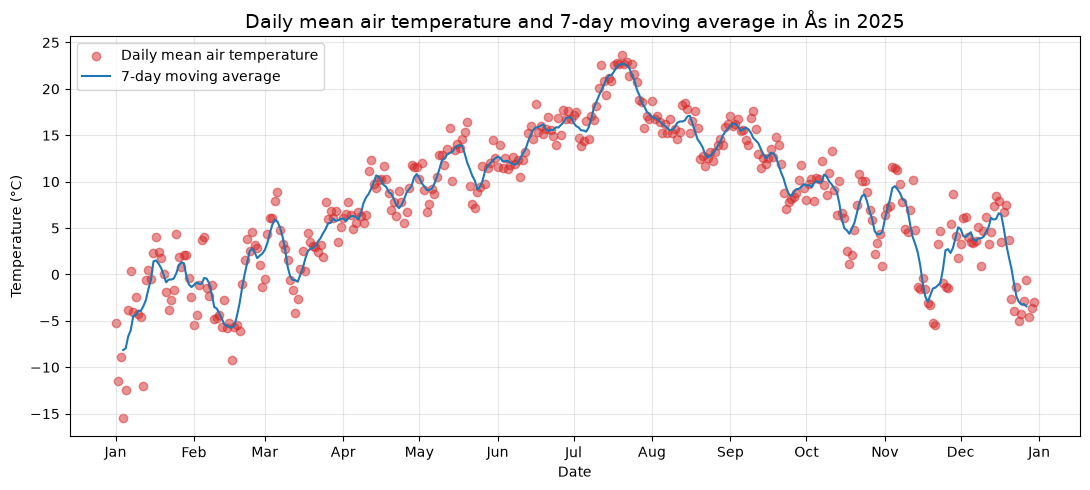

In [79]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates



client_id_file = Path.home() / "frost_client_id.txt"       # reads the client ID from a file in the home directory
client_id = client_id_file.read_text().strip()             # removes any spaces from the client ID string

endpoint = "https://frost.met.no/observations/v0.jsonld"    # Frost API endpoint for observations



parameters = {                                              # parameters for the API request (daily mean air temperature)
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))    # make the GET request to the Frost API with the specified parameters and authentication
json_data = r.json()                                            # extract the data from the response

if r.status_code == 200:                                  # check if the request was successful (status code 200 indicates success)
    print('Temperature data retrieved from frost.met.no!')
else:
    print(f"Error: {r.status_code} - {json_data['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                     # stop the script here so the later code does not crash with a confusing KeyError

rows = []                                   # create an empty list to store the data rows for the DataFrame
for item in json_data["data"]:              # iterate through each item in the "data" field
    observation = item["observations"][0]   # one daily mean per reference time
    rows.append(                            # adds the data for each observation to the rows list as a dictionary with keys "time" and "temperature"
        {
            "time": pd.to_datetime(item["referenceTime"]),
            "temperature": observation["value"],
        }
    )

df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)      # creates a dataframe from the rows list, sorts it by time, and resets the index



def moving_average(values, window=7):       # function to calculate theseven day moving average
    averages = []                           # create an empty list to store the moving averages
    for i in range(len(values) - window + 1):               # iterate through the values, stopping when there are not enough values left to calculate a full window
        averages.append(values[i:i + window].mean())        # calculate the mean of the current window and append it to the averages list
    return averages



dates = df["time"][3:len(df) - 3]     # dates corresponding to the moving averages (the first and last three days are excluded since they do not have a full 7-day window)



fig, ax = plt.subplots(figsize=(11, 5))         # creates a figure and axes for the plot with a specified size
ax.scatter(df["time"], df["temperature"], color="tab:red", alpha=0.5, label="Daily mean air temperature")      # plots the date on the x-axis and daily mean air temperature data on the y-axis as a scatter plot
ax.plot(dates, moving_average(df["temperature"]), color="tab:blue", label="7-day moving average")      # plots the 7-day moving average of the daily mean air temperature data on the y-axis as a line plot
ax.set_title("Daily mean air temperature and 7-day moving average in Ås in 2025", fontsize=14)
ax.xaxis.set_major_locator(mdates.MonthLocator())           # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
fig.tight_layout()
plt.show()
